<a href="https://colab.research.google.com/github/ulisesjcaroflores/Lab1/blob/main/Lab2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from plotnine import *

avocado_clean = pd.read_csv('/content/avocado-updated-2020.csv')
avocado_clean.head()


,date,average_price,total_volume,4046,4225,4770,total_bags,small_bags,large_bags,xlarge_bags,type,year,geography
0,2015-01-04,1.22,40873.28,2819.50,28287.42,49.90,9716.46,9186.93,529.53,0.0,conventional,2015,Albany
1,2015-01-04,1.79,1373.95,57.42,153.88,0.00,1162.65,1162.65,0.00,0.0,organic,2015,Albany
2,2015-01-04,1.00,435021.49,364302.39,23821.16,82.15,46815.79,16707.15,30108.64,0.0,conventional,2015,Atlanta
3,2015-01-04,1.76,3846.69,1500.15,938.35,0.00,1408.19,1071.35,336.84,0.0,organic,2015,Atlanta
4,2015-01-04,1.08,788025.06,53987.31,552906.04,39995.03,141136.68,137146.07,3990.61,0.0,conventional,2015,Baltimore/Washington


**This dataset contains the sales of avocados across various U.S. markets over a certain time period ranging from 2014 - 2020. Other metrics includes are average price of the avocado, different sizes through a specific code, the number of avocados sold in a certain size of bag, and whether the avocado was organic or conventional. A interesting detail is the geogrpahy as it is a combination of cities, states, regions, and national total.**

**This helps display the unique values of the geography**

In [27]:
avocado_clean["geography"].value_counts()

,count
geography,
Albany,612
Atlanta,612
Baltimore/Washington,612
Boise,612
Boston,612
Buffalo/Rochester,612
California,612
Charlotte,612
Chicago,612


In [39]:
len(avocado_clean)

33045

**Here we are mapping the geogprahy to a specific category: city, state, region, national**

In [28]:
avocado_clean["geo_type"] = avocado_clean["geography"].map({
    "Total U.S.": "national",
    "South Carolina": "state",
    "California": "region",
    "West": "region",
    "Great Lakes": "region",
    "Midsouth": "region",
    "Northeast": "region",
    "Northern New England": "region",
    "Plains": "region",
    "Southeast": "region",
    "South Central": "region",
    "West Tex/New Mexico": "region",
    "Baltimore/Washington": "metro",
    "Buffalo/Rochester": "metro",
    "Cincinnati/Dayton": "metro",
    "Dallas/Ft. Worth": "metro",
    "Harrisburg/Scranton": "metro",
    "Hartford/Springfield": "metro",
    "Miami/Ft. Lauderdale": "metro",
    "New Orleans/Mobile": "metro",
    "Phoenix/Tucson": "metro",
    "Raleigh/Greensboro": "metro",
    "Richmond/Norfolk": "metro"
})

# Apply fillna to the created 'geo_type' column
avocado_clean["geo_type"] = avocado_clean["geo_type"].fillna("city")
avocado_clean.head()

,date,average_price,total_volume,4046,4225,4770,total_bags,small_bags,large_bags,xlarge_bags,type,year,geography,geo_type
0,2015-01-04,1.22,40873.28,2819.50,28287.42,49.90,9716.46,9186.93,529.53,0.0,conventional,2015,Albany,city
1,2015-01-04,1.79,1373.95,57.42,153.88,0.00,1162.65,1162.65,0.00,0.0,organic,2015,Albany,city
2,2015-01-04,1.00,435021.49,364302.39,23821.16,82.15,46815.79,16707.15,30108.64,0.0,conventional,2015,Atlanta,city
3,2015-01-04,1.76,3846.69,1500.15,938.35,0.00,1408.19,1071.35,336.84,0.0,organic,2015,Atlanta,city
4,2015-01-04,1.08,788025.06,53987.31,552906.04,39995.03,141136.68,137146.07,3990.61,0.0,conventional,2015,Baltimore/Washington,metro


**We are renaming the sizes of avocado based on the PLU codes.**

In [10]:
avocado_rename = {
    "4046": "small",
    "4225": "large",
    "4770": "extra large"
}

avocado_clean = avocado_clean.rename(columns=avocado_rename)
avocado_clean.head()

,date,average_price,total_volume,small,large,extra large,total_bags,small_bags,large_bags,xlarge_bags,type,year,geography,geo_type
0,2015-01-04,1.22,40873.28,2819.50,28287.42,49.90,9716.46,9186.93,529.53,0.0,conventional,2015,Albany,city
1,2015-01-04,1.79,1373.95,57.42,153.88,0.00,1162.65,1162.65,0.00,0.0,organic,2015,Albany,city
2,2015-01-04,1.00,435021.49,364302.39,23821.16,82.15,46815.79,16707.15,30108.64,0.0,conventional,2015,Atlanta,city
3,2015-01-04,1.76,3846.69,1500.15,938.35,0.00,1408.19,1071.35,336.84,0.0,organic,2015,Atlanta,city
4,2015-01-04,1.08,788025.06,53987.31,552906.04,39995.03,141136.68,137146.07,3990.61,0.0,conventional,2015,Baltimore/Washington,metro


**We are looking for the region that has the highest sales of organic small hass avocados in 2017**

In [16]:
avocado_smallsales = avocado_clean[(avocado_clean['geo_type'] == 'region') & (avocado_clean['type'] == 'organic') & (avocado_clean['year'] == 2017)]
avocado_smallsales.groupby('geography')['small'].sum().sort_values(ascending=False).head(1)

,small
geography,
West,1870206.29


**We found that the West region had the highest sales of organic small hass avocados in 2017 with a value of 1870206.29**

In [53]:
# Convert the 'date' column to datetime objects
avocado_clean['date'] = pd.to_datetime(avocado_clean['date'])

# Extract year, month, and day using apply and lambda (alternative to .dt)
avocado_clean['year'] = avocado_clean['date'].apply(lambda x: x.year)
avocado_clean['month'] = avocado_clean['date'].apply(lambda x: x.month)
avocado_clean['day'] = avocado_clean['date'].apply(lambda x: x.day)

avocado_clean.head()

,date,average_price,total_volume,small,large,extra large,total_bags,small_bags,large_bags,xlarge_bags,type,year,geography,geo_type,month,day
0,2015-01-04,1.22,40873.28,2819.50,28287.42,49.90,9716.46,9186.93,529.53,0.0,conventional,2015,Albany,city,1,4
1,2015-01-04,1.79,1373.95,57.42,153.88,0.00,1162.65,1162.65,0.00,0.0,organic,2015,Albany,city,1,4
2,2015-01-04,1.00,435021.49,364302.39,23821.16,82.15,46815.79,16707.15,30108.64,0.0,conventional,2015,Atlanta,city,1,4
3,2015-01-04,1.76,3846.69,1500.15,938.35,0.00,1408.19,1071.35,336.84,0.0,organic,2015,Atlanta,city,1,4
4,2015-01-04,1.08,788025.06,53987.31,552906.04,39995.03,141136.68,137146.07,3990.61,0.0,conventional,2015,Baltimore/Washington,city,1,4


In [14]:
avocado_clean['date'] = pd.to_datetime(avocado_clean['date'])
avocado_clean['year'] = avocado_clean['date'].dt.year
avocado_clean['month'] = avocado_clean['date'].dt.month_name()
avocado_clean['day'] = avocado_clean['date'].dt.day
avocado_clean.head()

,date,average_price,total_volume,small,large,extra large,total_bags,small_bags,large_bags,xlarge_bags,type,year,geography,geo_type,month,day
0,2015-01-04,1.22,40873.28,2819.50,28287.42,49.90,9716.46,9186.93,529.53,0.0,conventional,2015,Albany,city,January,4
1,2015-01-04,1.79,1373.95,57.42,153.88,0.00,1162.65,1162.65,0.00,0.0,organic,2015,Albany,city,January,4
2,2015-01-04,1.00,435021.49,364302.39,23821.16,82.15,46815.79,16707.15,30108.64,0.0,conventional,2015,Atlanta,city,January,4
3,2015-01-04,1.76,3846.69,1500.15,938.35,0.00,1408.19,1071.35,336.84,0.0,organic,2015,Atlanta,city,January,4
4,2015-01-04,1.08,788025.06,53987.31,552906.04,39995.03,141136.68,137146.07,3990.61,0.0,conventional,2015,Baltimore/Washington,metro,January,4


**Looking for the month with the highest average volume of avocado sales**

In [21]:
high_avgvolume = avocado_clean[avocado_clean["geo_type"] == 'national']
high_avgvolume.groupby('month')['total_volume'].mean().sort_values(ascending=False).head(1)

,total_volume
month,
May,2.293203e+07


**Plot size comparison of metro area**

In [23]:
top5_metrovolume = avocado_clean[avocado_clean["geo_type"] == 'metro']
top5_metrovolume.groupby('geography')['total_volume'].sum().sort_values(ascending=False).head(5)

,total_volume
geography,
Dallas/Ft. Worth,4.362042e+08
Phoenix/Tucson,3.825234e+08
Baltimore/Washington,2.767646e+08
Miami/Ft. Lauderdale,2.317448e+08
Raleigh/Greensboro,1.079793e+08


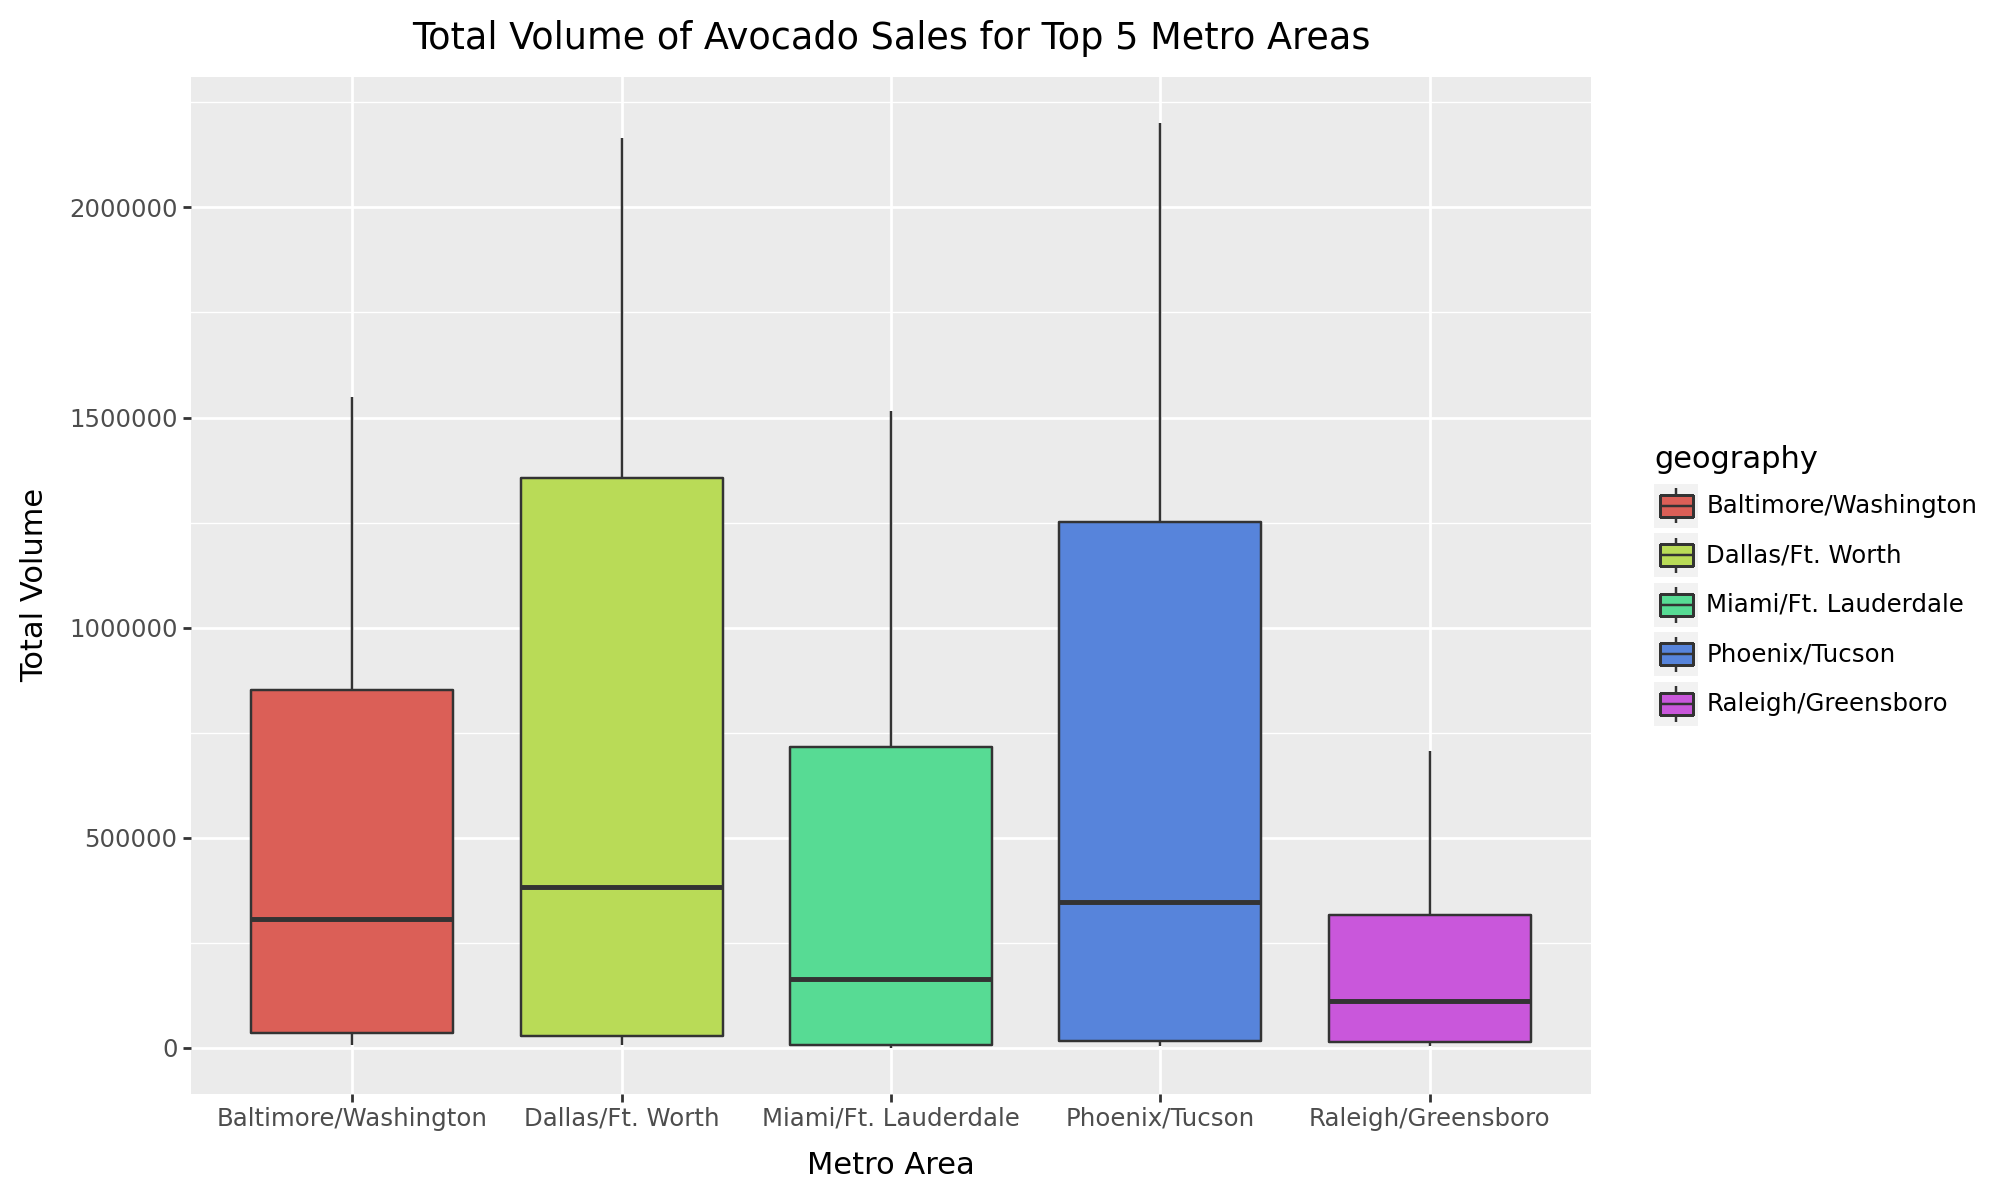

In [34]:
top5_metro = top5_metrovolume.groupby('geography')['total_volume'].sum().sort_values(ascending=False).head(5).index
top5_metrovolume = top5_metrovolume[top5_metrovolume['geography'].isin(top5_metro)]
ggplot(top5_metrovolume, aes(x='geography', y='total_volume', fill='geography')) + geom_boxplot() + labs(title="Total Volume of Avocado Sales for Top 5 Metro Areas", x="Metro Area", y="Total Volume") + theme(figure_size=(10, 6))